In [85]:
import numpy as np
from scipy.integrate import solve_ivp
from tools import Config
import matplotlib.pyplot as plt
from scipy.optimize import root
from tools_eco import followpars, followpars_with_eqnature, foodweb, foodweb_jacobian

# Initial parameter test

In [86]:
pars_test = Config(dict(muC=0.01, muH=0.01, eH=0.3, aH=1, pCH=1.2,
                   omegaH=0.2, ThH=1, ThU=0.1, omegaU=0.3, eU=0.3,
                   pCU=0.2, aU=0.1, rH=0.5, K=0.6, nu=0.1))

In [87]:
y0 = [0.1, 0.21, 2]
Tmax = 8000
tspan = np.linspace(0, Tmax, 2000)

sol0 = solve_ivp(lambda t, y: foodweb(y, pars_test), [0, Tmax], y0,t_eval=tspan)
sol0.y[0, -1], sol0.y[1, -1], sol0.y[2, -1]


(np.float64(1.8402325656653193),
 np.float64(0.18074497390290756),
 np.float64(1.7400966563464998e-07))

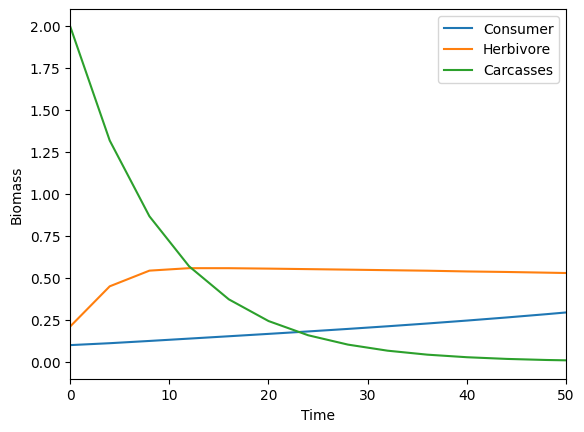

In [88]:
Tend = 50
plt.plot(tspan, sol0.y[0], label='Consumer')
plt.plot(tspan, sol0.y[1], label='Herbivore')
plt.plot(tspan, sol0.y[2], label='Carcasses')
plt.xlim(0, Tend)
plt.xlabel('Time')
plt.ylabel('Biomass')
plt.legend()
plt.show()

# Follow K

In [89]:
pars = Config(dict(muC=0.01, muH=0.01, eH=0.3, aH=1, pCH=1.2,
                   omegaH=0.2, ThH=1, ThU=0.1, omegaU=0.3, eU=0.3,
                   pCU=0.2, aU=0.1, rH=0.5, K=1, nu=0.1))
y0 = [1.9, 0.21, 2]
eq = root(foodweb, y0, args=(pars,))
print(eq.x)
bp1, e1, n1, c1 = followpars_with_eqnature(foodweb, foodweb_jacobian, pars, 'K', 
                                          np.linspace(1, 6, 50), eq.x)
bp2, e2, n2, c2 = followpars_with_eqnature(foodweb, foodweb_jacobian, pars, 'K', 
                                          np.linspace(1, 0.01, 50), eq.x)
eKlist   = bp2[::-1] + bp1[1:]          
eqK      = np.vstack([e2[::-1], e1[1:]])
eqnatcol = c2[::-1] + c1[1:]
eqnature = n2[::-1] + n1[1:]

[ 2.16692010e+00  1.80744992e-01 -2.04036323e-10]


In [90]:
idx = [i for i in range(1, len(eqnature)) if eqnature[i] != eqnature[i-1]]
idx#, eKlist[idx[0]], eKlist[idx[1]], eKlist[idx[2]]

[9, 34, 93]

Text(0.5, 1.0, 'Carcasses')

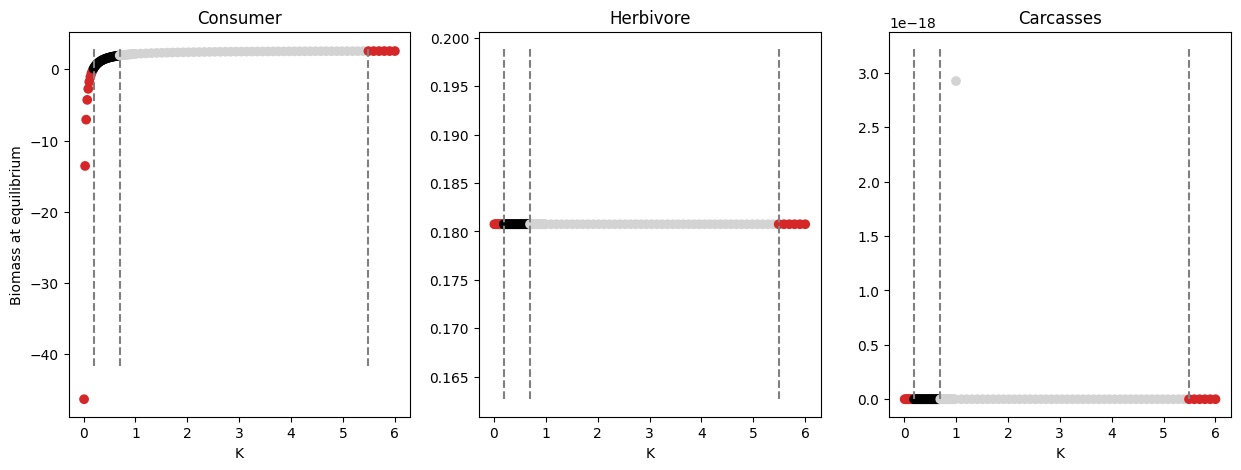

In [91]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))
for i, ax in enumerate(axes):
    ax.scatter(eKlist, eqK[:, i], color = eqnatcol)
    ax.set_xlabel('K')
    ymin = min(eqK[:, i]) - min(eqK[:, i])/10
    ymax = max(eqK[:, i]) + max(eqK[:, i])/10
    ax.vlines(x=[eKlist[i] for i in idx], ymin=ymin, 
              ymax=ymax, color='gray', linestyles='dashed')
axes[0].set_title('Consumer')
axes[0].set_ylabel('Biomass at equilibrium')
axes[1].set_title('Herbivore')
axes[2].set_title('Carcasses')

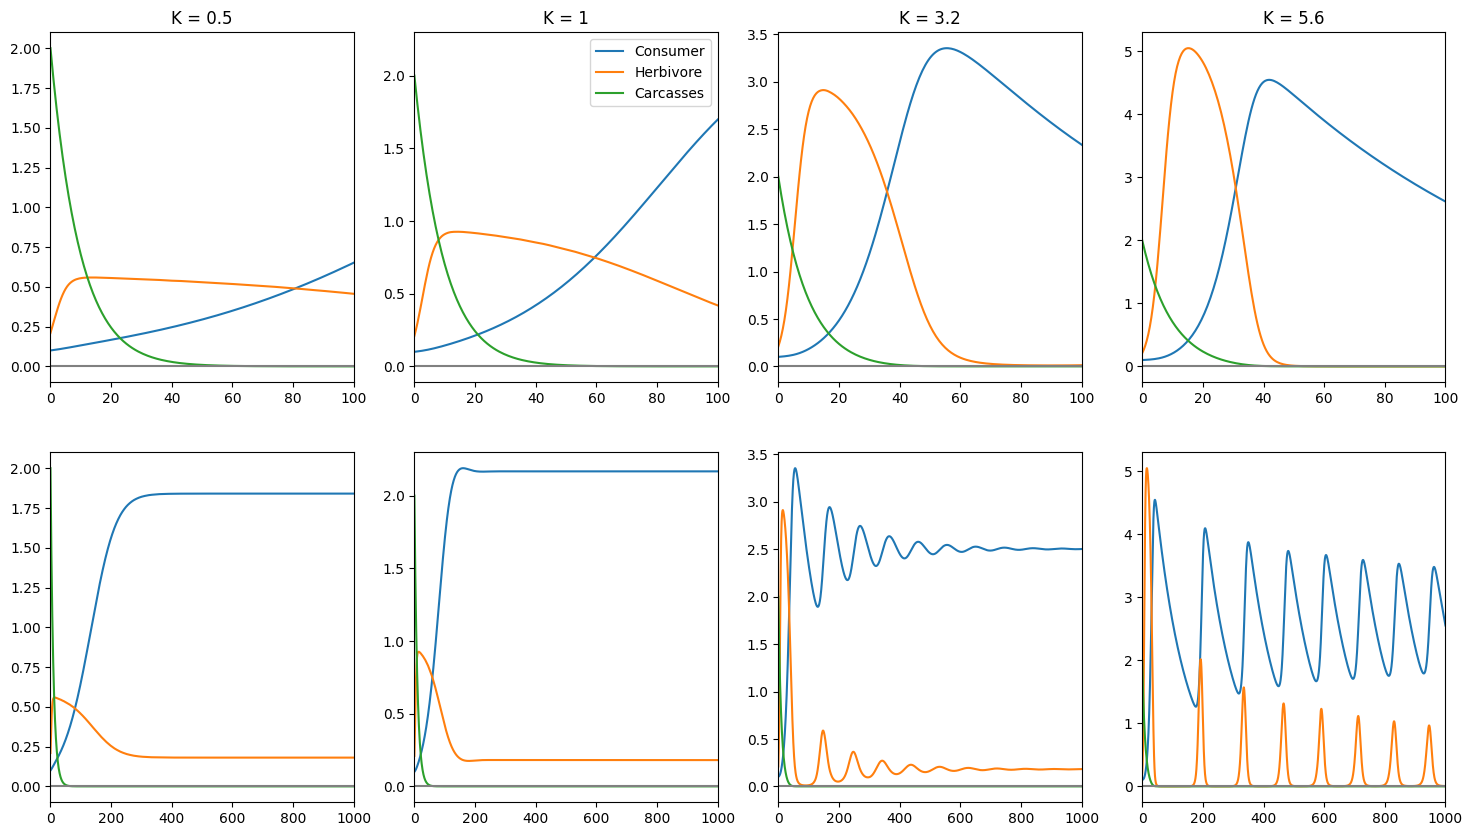

In [92]:
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(18, 10))
parnsol = Config(dict(muC=0.01, muH=0.01, eH=0.3, aH=1, pCH=1.2,
                   omegaH=0.2, ThH=1, ThU=0.1, omegaU=0.3, eU=0.3,
                   pCU=0.2, aU=0.1, rH=0.5, K=0.5, nu=0.1))
y0 = [0.1, 0.21, 2]
Tmax = 1000
Tend = 100
tspan = np.linspace(0, Tmax, 2000)
labellist = ["Consumer", "Herbivore", "Carcasses"]
nsol = solve_ivp(lambda t, y: foodweb(y, pars_test), [0, Tmax], y0,t_eval=tspan)  

for i in range(3):
    axes[0, 0].plot(tspan, nsol.y[i])                 
    axes[1, 0].plot(tspan, nsol.y[i])                 
axes[0, 0].set_xlim(0, Tend)
axes[0, 0].set_title(f'K = {parnsol.K}')
axes[1, 0].set_xlim(0, Tmax)
axes[0, 0].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')
axes[1, 0].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')
parnsol.K = 1
nsol = solve_ivp(lambda t, y: foodweb(y, parnsol), [0, Tmax], y0,t_eval=tspan)
for i in range(3):
    axes[0, 1].plot(tspan, nsol.y[i], label=labellist[i])
    axes[1, 1].plot(tspan, nsol.y[i], label=labellist[i])
axes[0, 1].legend()
axes[0, 1].set_xlim(0, Tend)
axes[0, 1].set_title(f'K = {parnsol.K}')
axes[1, 1].set_xlim(0, Tmax)
axes[0, 1].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')
axes[1, 1].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')

parnsol.K = 3.2
nsol = solve_ivp(lambda t, y: foodweb(y, parnsol), [0, Tmax], y0,t_eval=tspan)
for i in range(3):
    axes[0, 2].plot(tspan, nsol.y[i])
    axes[1, 2].plot(tspan, nsol.y[i])
axes[0, 2].set_xlim(0, Tend)
axes[0, 2].set_title(f'K = {parnsol.K}')
axes[1, 2].set_xlim(0, Tmax)
axes[0, 2].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')
axes[1, 2].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')

parnsol.K = 5.6
nsol = solve_ivp(lambda t, y: foodweb(y, parnsol), [0, Tmax], y0,t_eval=tspan)
for i in range(3):
    axes[0, 3].plot(tspan, nsol.y[i])
    axes[1, 3].plot(tspan, nsol.y[i])
axes[0, 3].set_xlim(0, Tend)
axes[0, 3].set_title(f'K = {parnsol.K}')
axes[1, 3].set_xlim(0, Tmax)
axes[0, 3].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')
axes[1, 3].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')

# Following ThU

In [93]:
pars = Config(dict(muC=0.01, muH=0.01, eH=0.3, aH=1, pCH=1.2,
                   omegaH=0.2, ThH=1, ThU=0.1, omegaU=0.3, eU=0.3,
                   pCU=0.2, aU=0.1, rH=0.5, K=1.6, nu=0.1))
y0 = [1.9, 0.21, 2]
eq = root(foodweb, y0, args=(pars,))
bp1, e1, n1, c1 = followpars_with_eqnature(foodweb, foodweb_jacobian, pars, 'ThU', 
                                          np.linspace(0.1, 1, 50), eq.x)
bp2, e2, n2, c2 = followpars_with_eqnature(foodweb, foodweb_jacobian, pars, 'ThU', 
                                          np.linspace(0.1, 0.01, 50), eq.x)
eThUlist   = bp2[::-1] + bp1[1::] 
eqThU     = np.vstack([e2[::-1], e1[1:]])
eqnatcol = c2[::-1] + c1[1:]
eqnature = n2[::-1] + n1[1:]

Text(0, 0.5, 'Biomass at equilibrium')

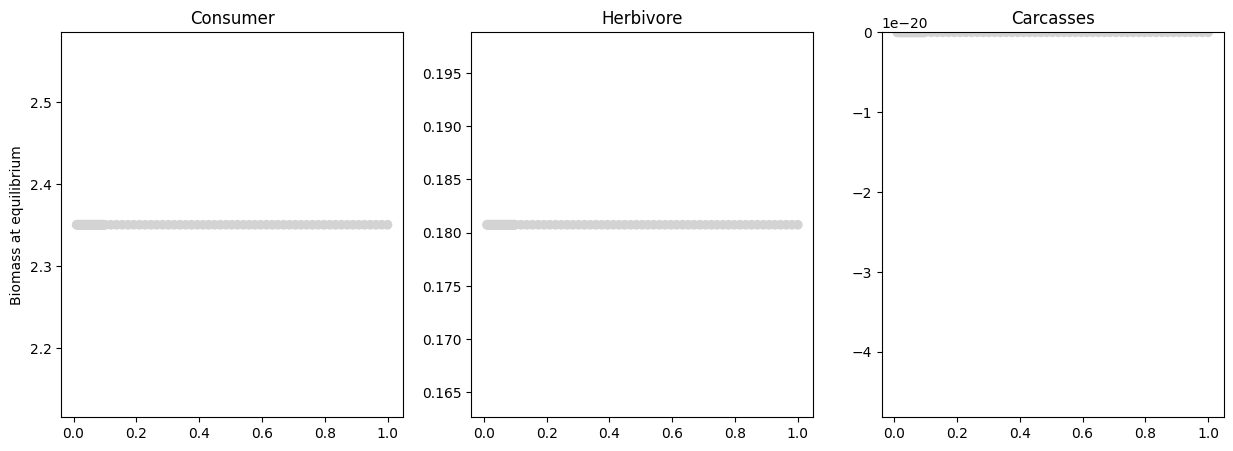

In [94]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))
for i, ax in enumerate(axes):
    ax.scatter(eThUlist, eqThU[:, i], color = eqnatcol)
    ymin = min(eqThU[:, i]) - min(eqThU[:, i])/10
    ymax = max(eqThU[:, i]) + max(eqThU[:, i])/10
    ax.set_ylim(ymin, ymax)
axes[0].set_title('Consumer')
axes[1].set_title('Herbivore')
axes[2].set_title('Carcasses')
axes[0].set_ylabel('Biomass at equilibrium')

In [95]:
pars = Config(dict(muC=0.01, muH=0.01, eH=0.3, aH=1, pCH=1.2,
                   omegaH=0.2, ThH=1, ThU=0.1, omegaU=0.3, eU=0.3,
                   pCU=0.2, aU=0.1, rH=0.5, K=5.6, nu=0.1))
y0 = [1.9, 0.21, 2]
eq = root(foodweb, y0, args=(pars,))
print(eq.x)
bp1, e1, n1, c1 = followpars_with_eqnature(foodweb, foodweb_jacobian, pars, 'ThU', 
                                          np.linspace(0.1, 1, 50), eq.x)
bp2, e2, n2, c2 = followpars_with_eqnature(foodweb, foodweb_jacobian, pars, 'ThU', 
                                          np.linspace(0.1, 0.01, 50), eq.x)
eThUlist   = bp2[::-1] + bp1[1::] 
eqThU     = np.vstack([e2[::-1], e1[1:]])
eqnatcol = c2[::-1] + c1[1:]
eqnature = n2[::-1] + n1[1:]

[ 2.56944580e+00  1.80744992e-01 -5.77771079e-11]


Text(0.5, 1.0, 'Carcasses')

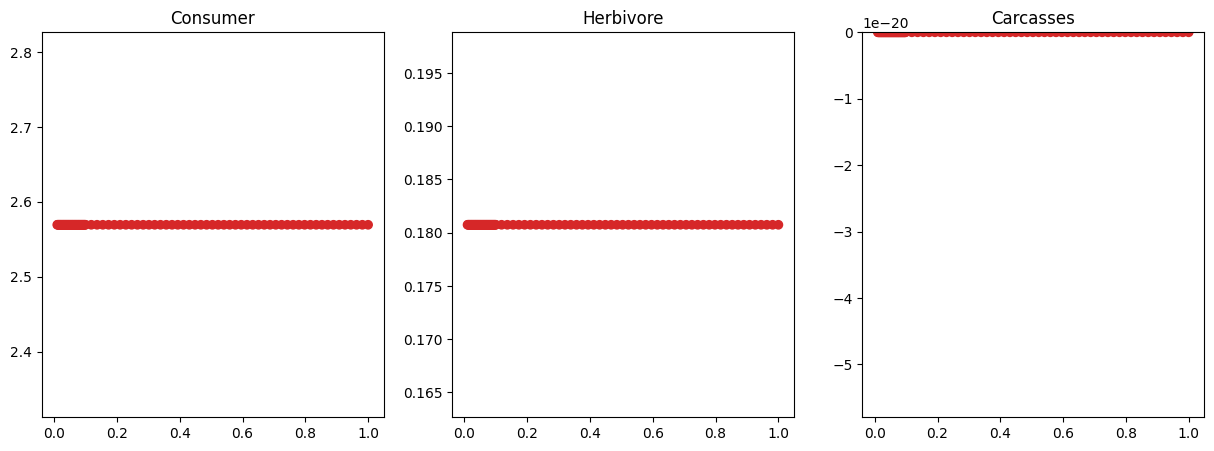

In [96]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))
for i, ax in enumerate(axes):
    ax.scatter(eThUlist, eqThU[:, i], color = eqnatcol)
    ymin = min(eqThU[:, i]) - min(eqThU[:, i])/10
    ymax = max(eqThU[:, i]) + max(eqThU[:, i])/10
    ax.set_ylim(ymin, ymax)
axes[0].set_title('Consumer')
axes[1].set_title('Herbivore')
axes[2].set_title('Carcasses')

# Following ThH

In [97]:
pars = Config(dict(muC=0.01, muH=0.01, eH=0.3, aH=1, pCH=1.2,
                   omegaH=0.2, ThH=1, ThU=0.1, omegaU=0.3, eU=0.3,
                   pCU=0.2, aU=0.1, rH=0.5, K=0.6, nu=0.1))
y0 = [1.9, 0.21, 2]
eq = root(foodweb, y0, args=(pars,))
print(eq.x)
bp1, e1, n1, c1 = followpars_with_eqnature(foodweb, foodweb_jacobian, pars, 'ThH', 
                                          np.linspace(1, 10.5, 100), eq.x)
bp2, e2, n2, c2 = followpars_with_eqnature(foodweb, foodweb_jacobian, pars, 'ThH', 
                                          np.linspace(1, 0.1, 50), eq.x)
eThHlist   = bp2[::-1] + bp1[1::] 
eqThH     = np.vstack([e2[::-1], e1[1:]])
eqnatcol = c2[::-1] + c1[1:]
eqnature = n2[::-1] + n1[1:]


[1.84023258e+00 1.80744992e-01 3.59158357e-14]


Text(0.5, 1.0, 'Carcasses')

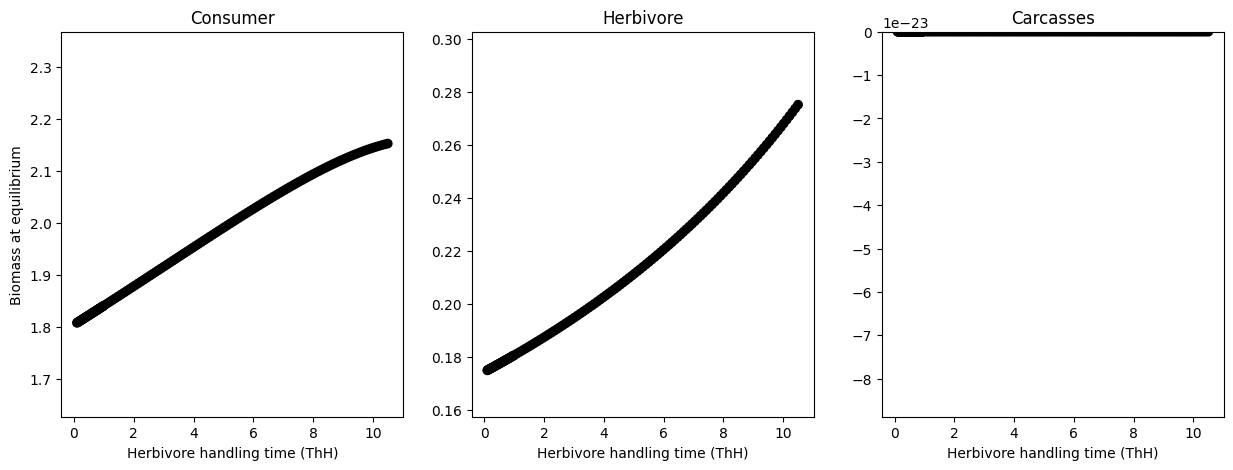

In [98]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))
for i, ax in enumerate(axes):
    ax.scatter(eThHlist, eqThH[:, i], color = eqnatcol)
    ymin = min(eqThH[:, i]) - min(eqThH[:, i])/10
    ymax = max(eqThH[:, i]) + max(eqThH[:, i])/10
    ax.set_ylim(ymin, ymax)
    ax.set_xlabel('Herbivore handling time (ThH)')
axes[0].set_title('Consumer')
axes[0].set_ylabel('Biomass at equilibrium')
axes[1].set_title('Herbivore')
axes[2].set_title('Carcasses')

Text(0.5, 1.0, 'ThH = 5.6')

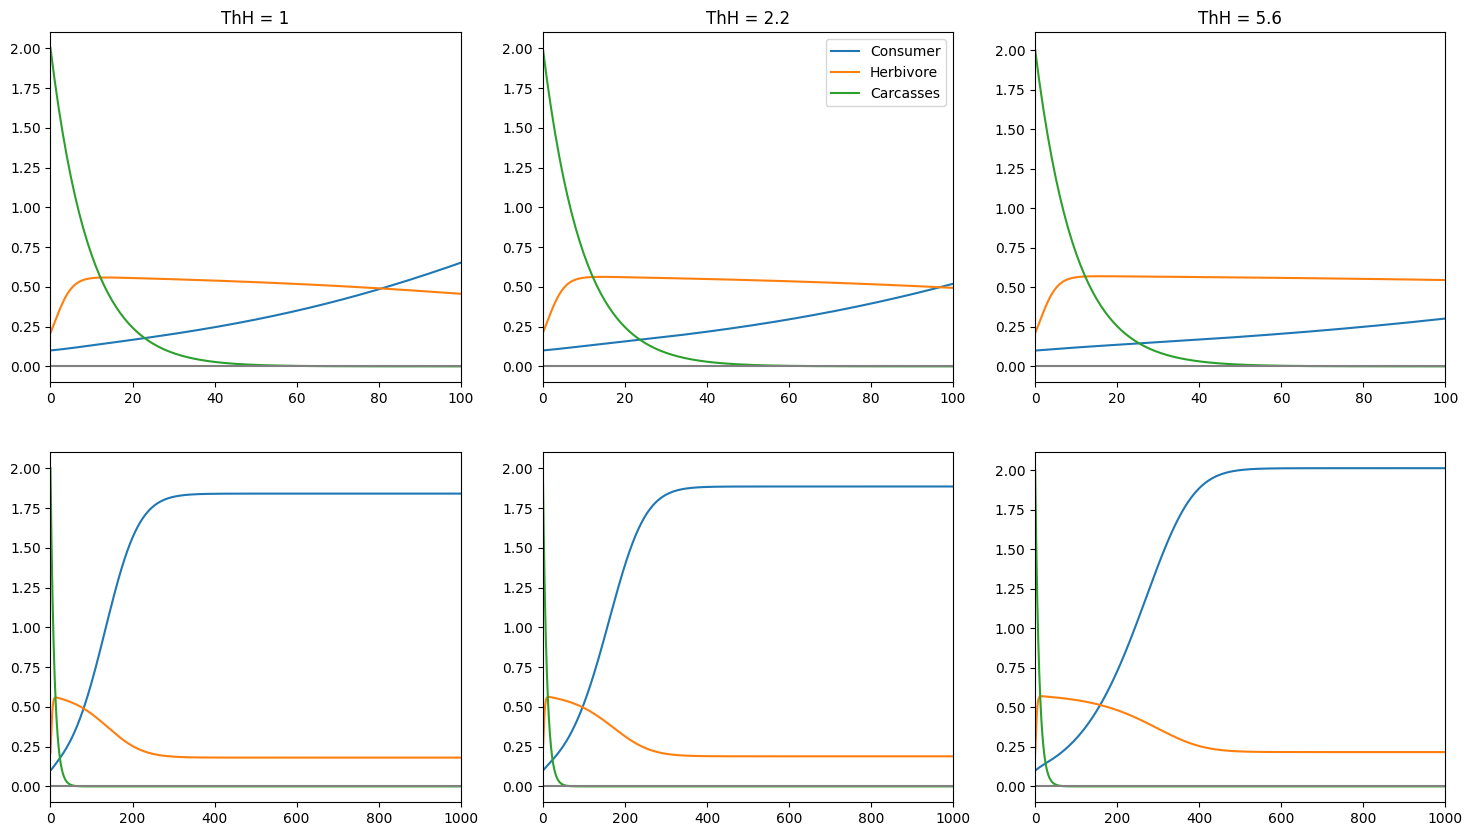

In [99]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
parnsol = Config(dict(muC=0.01, muH=0.01, eH=0.3, aH=1, pCH=1.2,
                   omegaH=0.2, ThH=1, ThU=0.1, omegaU=0.3, eU=0.3,
                   pCU=0.2, aU=0.1, rH=0.5, K=0.6, nu=0.1))
y0 = [0.1, 0.21, 2]
Tmax = 1000
Tend = 100
tspan = np.linspace(0, Tmax, 2000)
labellist = ["Consumer", "Herbivore", "Carcasses"]
nsol = solve_ivp(lambda t, y: foodweb(y, parnsol), [0, Tmax], y0,t_eval=tspan,
                 rtol=1e-8, atol=1e-10)

for i in range(3):
    axes[0, 0].plot(tspan, nsol.y[i])
    axes[1, 0].plot(tspan, nsol.y[i])
axes[0, 0].set_xlim(0, Tend)
axes[1, 0].set_xlim(0, Tmax)
axes[0, 0].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')
axes[1, 0].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')
axes[0, 0].set_title(f'ThH = {parnsol.ThH}')

parnsol.ThH = 2.2
nsol = solve_ivp(lambda t, y: foodweb(y, parnsol), [0, Tmax], y0,t_eval=tspan,
                 rtol=1e-8, atol=1e-10)
for i in range(3):
    axes[0, 1].plot(tspan, nsol.y[i], label=labellist[i])
    axes[1, 1].plot(tspan, nsol.y[i], label=labellist[i])
axes[0, 1].legend()
axes[0, 1].set_xlim(0, Tend)
axes[1, 1].set_xlim(0, Tmax)
axes[0, 1].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')
axes[1, 1].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')
axes[0, 1].set_title(f'ThH = {parnsol.ThH}')

parnsol.ThH = 5.6
nsol = solve_ivp(lambda t, y: foodweb(y, parnsol), [0, Tmax], y0,t_eval=tspan,
                 rtol=1e-8, atol=1e-10)
for i in range(3):
    axes[0, 2].plot(tspan, nsol.y[i])
    axes[1, 2].plot(tspan, nsol.y[i])
axes[0, 2].set_xlim(0, Tend)
axes[1, 2].set_xlim(0, Tmax)
axes[0, 2].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')
axes[1, 2].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')
axes[0, 2].set_title(f'ThH = {parnsol.ThH}')

In [100]:
pars = Config(dict(muC=0.01, muH=0.01, eH=0.3, aH=1, pCH=1.2,
                   omegaH=0.2, ThH=1, ThU=0.1, omegaU=0.3, eU=0.3,
                   pCU=0.2, aU=0.1, rH=0.5, K=5.6, nu=0.1))
y0 = [1.9, 0.21, 2]
eq = root(foodweb, y0, args=(pars,))
print(eq.x)
bp1, e1, n1, c1 = followpars_with_eqnature(foodweb, foodweb_jacobian, pars, 'ThH', 
                                          np.linspace(1, 1.5, 50), eq.x)
bp2, e2, n2, c2 = followpars_with_eqnature(foodweb, foodweb_jacobian, pars, 'ThH', 
                                          np.linspace(1, 0.1, 50), eq.x)
eThHlist   = bp2[::-1] + bp1[1::] 
eqThH     = np.vstack([e2[::-1], e1[1:]])
eqnatcol = c2[::-1] + c1[1:]
eqnature = n2[::-1] + n1[1:]

[ 2.56944580e+00  1.80744992e-01 -5.77771079e-11]


Text(0.5, 1.0, 'Carcasses')

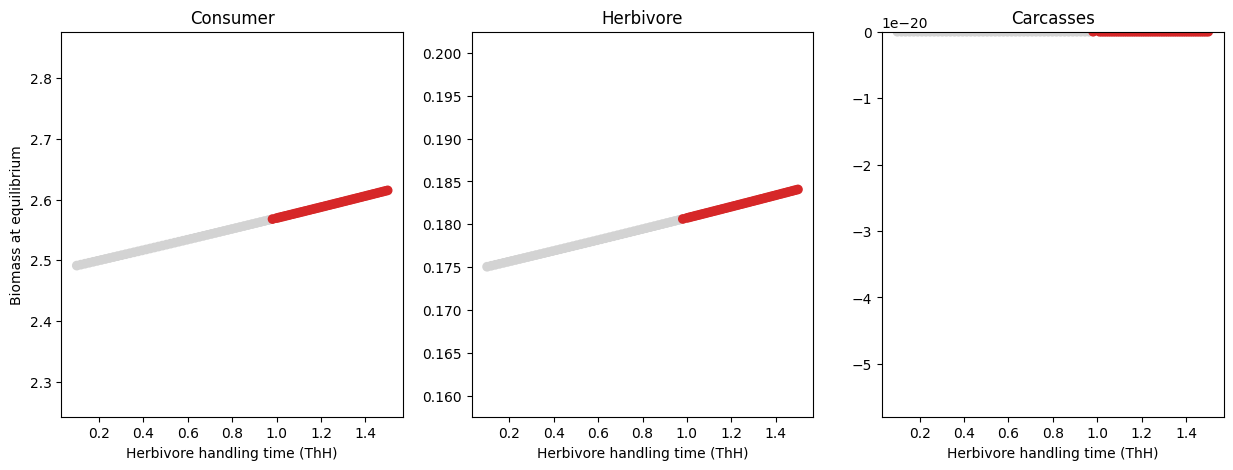

In [101]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))
for i, ax in enumerate(axes):
    ax.scatter(eThHlist, eqThH[:, i], color = eqnatcol)
    ymin = min(eqThH[:, i]) - min(eqThH[:, i])/10
    ymax = max(eqThH[:, i]) + max(eqThH[:, i])/10
    ax.set_ylim(ymin, ymax)
    ax.set_xlabel('Herbivore handling time (ThH)')
axes[0].set_title('Consumer')
axes[0].set_ylabel('Biomass at equilibrium')
axes[1].set_title('Herbivore')
axes[2].set_title('Carcasses')

Text(0.5, 1.0, 'ThH = 5.6')

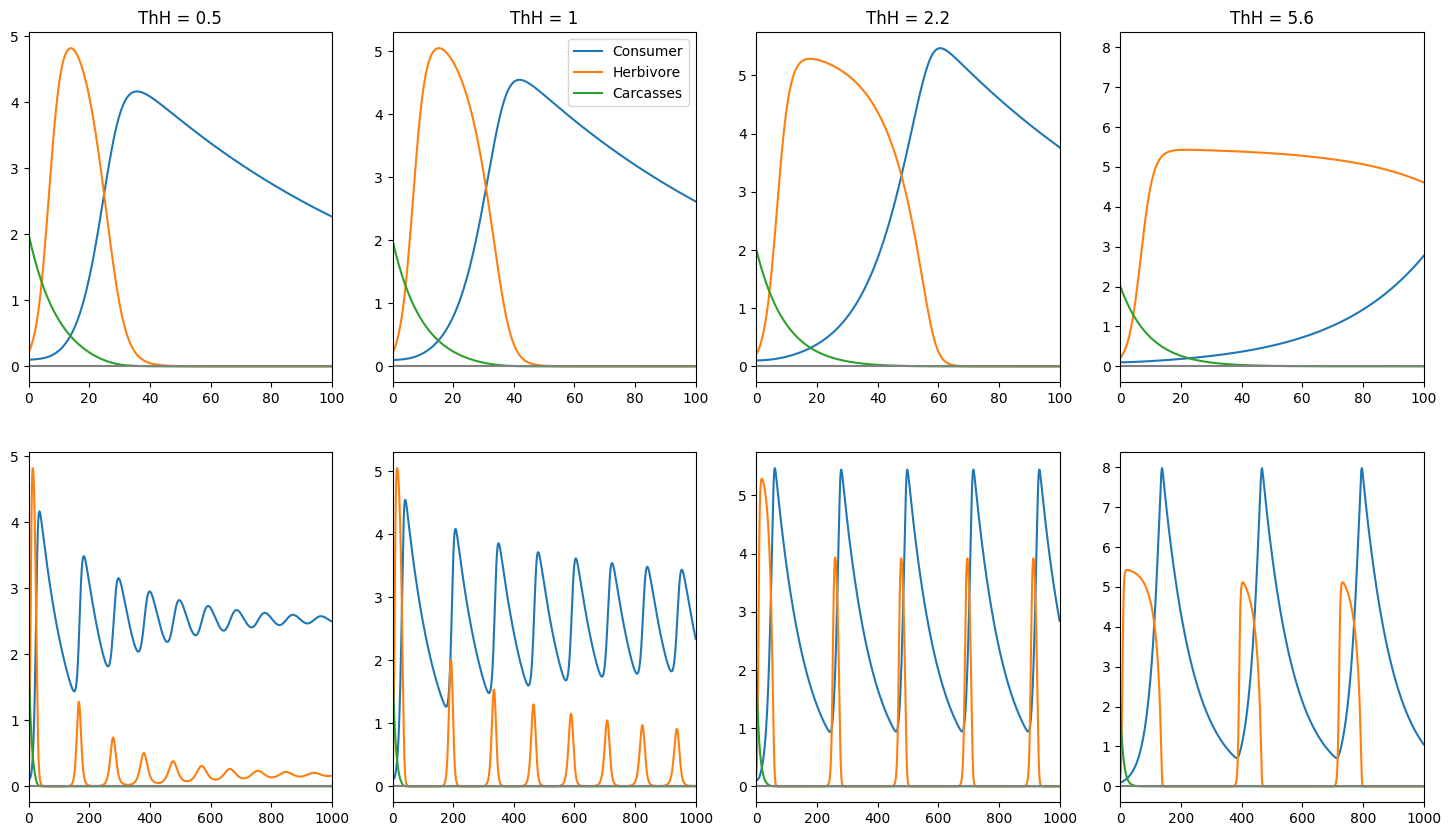

In [102]:
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(18, 10))
parnsol = Config(dict(muC=0.01, muH=0.01, eH=0.3, aH=1, pCH=1.2,
                   omegaH=0.2, ThH=0.5, ThU=0.1, omegaU=0.3, eU=0.3,
                   pCU=0.2, aU=0.1, rH=0.5, K=5.6, nu=0.1))
y0 = [0.1, 0.21, 2]
Tmax = 1000
Tend = 100
tspan = np.linspace(0, Tmax, 2000)
labellist = ["Consumer", "Herbivore", "Carcasses"]
nsol = solve_ivp(lambda t, y: foodweb(y, parnsol), [0, Tmax], y0,t_eval=tspan,
                 rtol=1e-8, atol=1e-10)

for i in range(3):
    axes[0, 0].plot(tspan, nsol.y[i])
    axes[1, 0].plot(tspan, nsol.y[i])
axes[0, 0].set_xlim(0, Tend)
axes[1, 0].set_xlim(0, Tmax)
axes[0, 0].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')
axes[1, 0].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')
axes[0, 0].set_title(f'ThH = {parnsol.ThH}')

parnsol.ThH = 1
nsol = solve_ivp(lambda t, y: foodweb(y, parnsol), [0, Tmax], y0,t_eval=tspan,
                 rtol=1e-8, atol=1e-10)
for i in range(3):
    axes[0, 1].plot(tspan, nsol.y[i], label=labellist[i])
    axes[1, 1].plot(tspan, nsol.y[i], label=labellist[i])
axes[0, 1].legend()
axes[0, 1].set_xlim(0, Tend)
axes[1, 1].set_xlim(0, Tmax)
axes[0, 1].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')
axes[1, 1].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')
axes[0, 1].set_title(f'ThH = {parnsol.ThH}')

parnsol.ThH = 2.2
nsol = solve_ivp(lambda t, y: foodweb(y, parnsol), [0, Tmax], y0,t_eval=tspan,
                 rtol=1e-8, atol=1e-10)
for i in range(3):
    axes[0, 2].plot(tspan, nsol.y[i])
    axes[1, 2].plot(tspan, nsol.y[i])
axes[0, 2].set_xlim(0, Tend)
axes[1, 2].set_xlim(0, Tmax)
axes[0, 2].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')
axes[1, 2].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')
axes[0, 2].set_title(f'ThH = {parnsol.ThH}')

parnsol.ThH = 5.6
nsol = solve_ivp(lambda t, y: foodweb(y, parnsol), [0, Tmax], y0,t_eval=tspan,
                 rtol=1e-8, atol=1e-10)
for i in range(3):
    axes[0, 3].plot(tspan, nsol.y[i])
    axes[1, 3].plot(tspan, nsol.y[i])
axes[0, 3].set_xlim(0, Tend)
axes[1, 3].set_xlim(0, Tmax)
axes[0, 3].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')
axes[1, 3].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')
axes[0, 3].set_title(f'ThH = {parnsol.ThH}')

# Following muH

In [103]:
pars = Config(dict(muC=0.01, muH=0.01, eH=0.3, aH=1, pCH=1.2,
                   omegaH=0.2, ThH=1, ThU=0.1, omegaU=0.3, eU=0.3,
                   pCU=0.2, aU=0.1, rH=0.5, K=0.6, nu=0.1))
y0 = [1.9, 0.21, 2]
eq = root(foodweb, y0, args=(pars,))
print(eq.x)
emuH, eqmuH, eqnature, eqnatcol = followpars_with_eqnature(foodweb, foodweb_jacobian, pars,
                                                            'muH', 
                                                            np.linspace(0.01, 0.6, 50), eq.x)

[1.84023258e+00 1.80744992e-01 3.59158357e-14]


Text(0.5, 1.0, 'Carcasses')

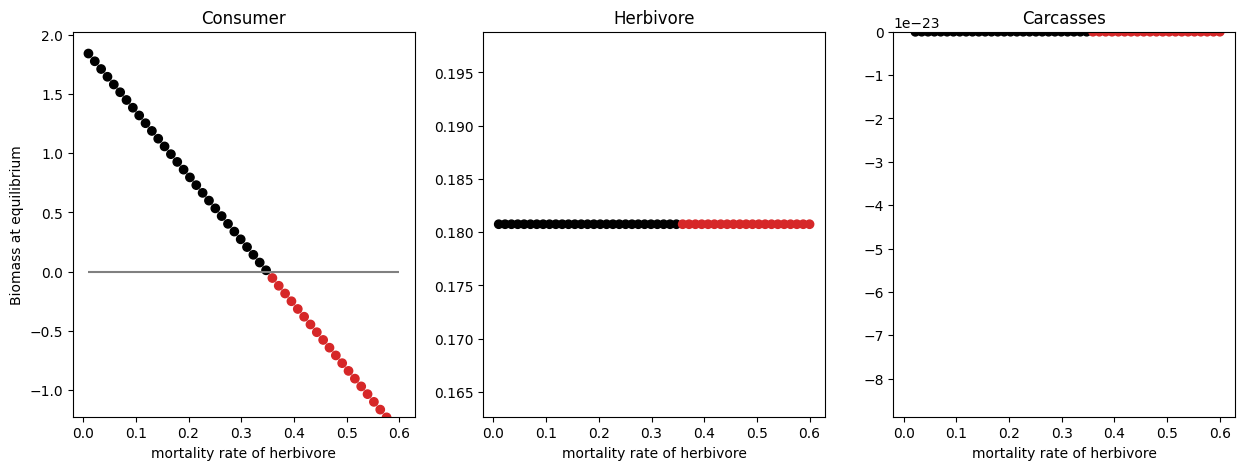

In [104]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))
for i, ax in enumerate(axes):
    ax.scatter(emuH, eqmuH[:, i], color = eqnatcol)
    ymin = min(eqmuH[:, i]) - min(eqmuH[:, i])/10
    ymax = max(eqmuH[:, i]) + max(eqmuH[:, i])/10
    ax.set_ylim(ymin, ymax)
    ax.set_xlabel('mortality rate of herbivore')
axes[0].set_title('Consumer')
axes[0].hlines(y=0, xmin=emuH[0], xmax=emuH[-1], color='gray')
axes[0].set_ylabel('Biomass at equilibrium')
axes[1].set_title('Herbivore')
axes[2].set_title('Carcasses')

In [105]:
pars = Config(dict(muC=0.01, muH=0.01, eH=0.3, aH=1, pCH=1.2,
                   omegaH=0.2, ThH=1, ThU=0.1, omegaU=0.3, eU=0.3,
                   pCU=0.2, aU=0.1, rH=0.5, K=5.6, nu=0.1))
y0 = [1.9, 0.21, 2]
eq = root(foodweb, y0, args=(pars,))
print(eq.x)
emuH, eqmuH, eqnature, eqnatcol = followpars_with_eqnature(foodweb, foodweb_jacobian, 
                                                           pars, 'muH', 
                                                           np.linspace(0.01, 0.6, 50), eq.x)

[ 2.56944580e+00  1.80744992e-01 -5.77771079e-11]


Text(0.5, 1.0, 'Carcasses')

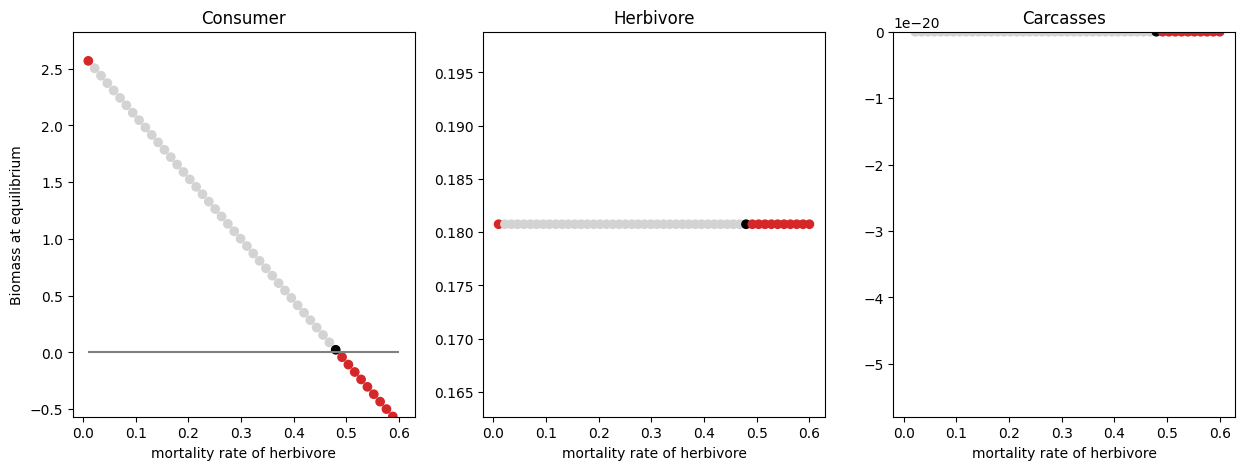

In [106]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))
for i, ax in enumerate(axes):
    ax.scatter(emuH, eqmuH[:, i], color = eqnatcol)
    ymin = min(eqmuH[:, i]) - min(eqmuH[:, i])/10
    ymax = max(eqmuH[:, i]) + max(eqmuH[:, i])/10
    ax.set_ylim(ymin, ymax)
    ax.set_xlabel('mortality rate of herbivore')
axes[0].set_title('Consumer')
axes[0].hlines(y=0, xmin=emuH[0], xmax=emuH[-1], color='gray')
axes[0].set_ylabel('Biomass at equilibrium')
axes[1].set_title('Herbivore')
axes[2].set_title('Carcasses')

In [107]:
pars = Config(dict(muC=0.01, muH=0.01, eH=0.3, aH=1, pCH=1.2,
                   omegaH=0.2, ThH=1, ThU=0.1, omegaU=0.3, eU=0.3,
                   pCU=0.2, aU=0.1, rH=0.5, K=0.6, nu=0.1))

y0 = [1.9, 0.21, 2]
eq = root(foodweb, y0, args=(pars,))
print(eq.x)
eaU, eqaU, eqnature, eqnatcol = followpars_with_eqnature(foodweb, foodweb_jacobian, 
                                                         pars, 'aU', 
                                                         np.linspace(0.1, 1.6, 50), eq.x)

[1.84023258e+00 1.80744992e-01 3.59158357e-14]


Text(0.5, 1.0, 'Carcasses')

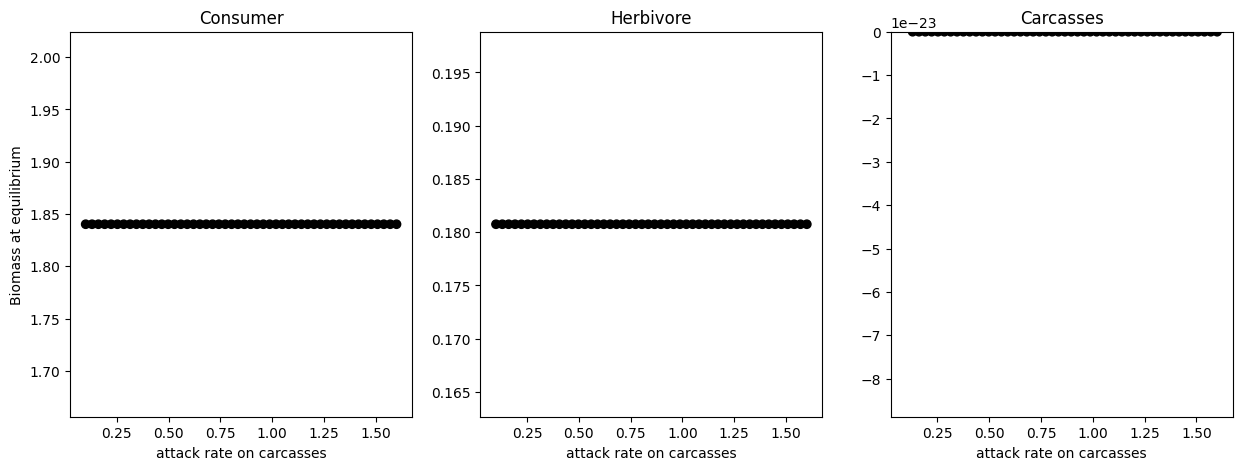

In [108]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))
for i, ax in enumerate(axes):
    ax.scatter(eaU, eqaU[:, i], color = eqnatcol)
    ymin = min(eqaU[:, i]) - min(eqaU[:, i])/10
    ymax = max(eqaU[:, i]) + max(eqaU[:, i])/10
    ax.set_ylim(ymin, ymax)
    ax.set_xlabel('attack rate on carcasses')
axes[0].set_title('Consumer')
axes[0].hlines(y=0, xmin=eaU[0], xmax=eaU[-1], color='gray')
axes[0].set_ylabel('Biomass at equilibrium')
axes[1].set_title('Herbivore')
axes[2].set_title('Carcasses')

In [109]:
pars = Config(dict(muC=0.01, muH=0.01, eH=0.3, aH=1, pCH=1.2,
                   omegaH=0.2, ThH=1, ThU=0.1, omegaU=0.3, eU=0.3,
                   pCU=0.2, aU=0.1, rH=0.5, K=0.6, nu=0.1))
y0 = [1.9, 0.21, 2]
eq = root(foodweb, y0, args=(pars,))
print(eq.x, eq.success)
bp1, e1, n1, c1 = followpars_with_eqnature(foodweb, foodweb_jacobian, pars, 'nu', 
                                          np.linspace(0.1, 0.5, 80), eq.x)
bp2, e2, n2, c2 = followpars_with_eqnature(foodweb, foodweb_jacobian, pars, 'nu', 
                                          np.linspace(0.1, 0.01, 80), eq.x)
enulist   = bp2[::-1] + bp1[1::] 
eqnu     = np.vstack([e2[::-1], e1[1:]])
eqnatcol = c2[::-1] + c1[1:]
eqnature = n2[::-1] + n1[1:]

[1.84023258e+00 1.80744992e-01 3.59158357e-14] True


Text(0.5, 1.0, 'Carcasses')

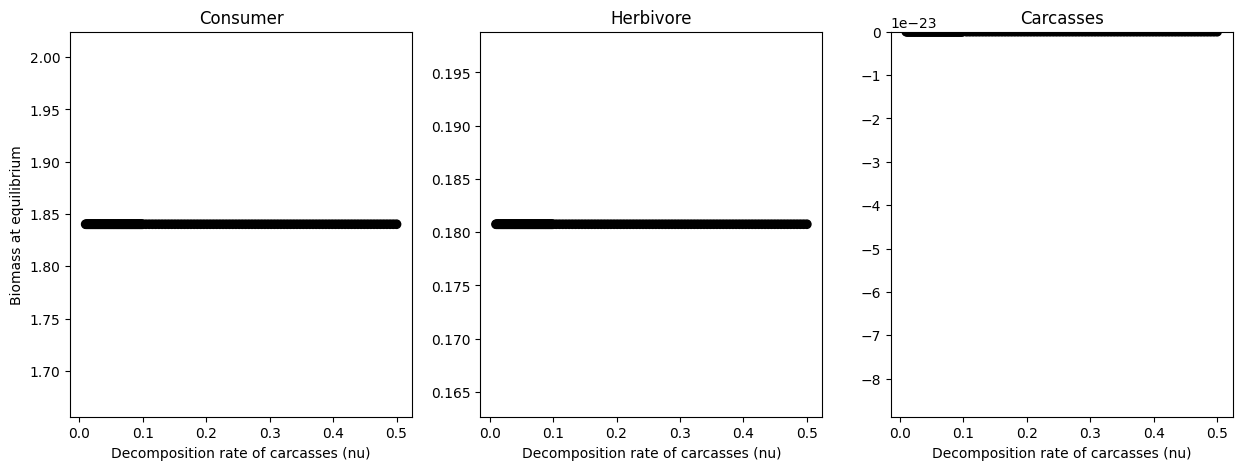

In [110]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))
for i, ax in enumerate(axes):
    ax.scatter(enulist, eqnu[:, i], color = eqnatcol)
    ymin = min(eqnu[:, i]) - min(eqnu[:, i])/10
    ymax = max(eqnu[:, i]) + max(eqnu[:, i])/10
    ax.set_ylim(ymin, ymax)
    ax.set_xlabel('Decomposition rate of carcasses (nu)')
axes[0].set_title('Consumer')
axes[0].hlines(y=0, xmin=enulist[0], xmax=enulist[-1], color='gray')
axes[0].set_ylabel('Biomass at equilibrium')
axes[1].set_title('Herbivore')
axes[2].set_title('Carcasses')

In [111]:
pars = Config(dict(muC=0.01, muH=0.01, eH=0.3, aH=1, pCH=1.2,
                   omegaH=0.2, ThH=1, ThU=0.1, omegaU=0.3, eU=0.3,
                   pCU=0.2, aU=0.1, rH=0.5, K=5.6, nu=0.1))
y0 = [1.9, 0.21, 2]
eq = root(foodweb, y0, args=(pars,))
print(eq.x, eq.success)
bp1, e1, n1, c1 = followpars_with_eqnature(foodweb, foodweb_jacobian, pars, 'nu', 
                                          np.linspace(0.1, 0.5, 80), eq.x)
bp2, e2, n2, c2 = followpars_with_eqnature(foodweb, foodweb_jacobian, pars, 'nu', 
                                          np.linspace(0.1, 0.01, 80), eq.x)
enulist   = bp2[::-1] + bp1[1::] 
eqnu     = np.vstack([e2[::-1], e1[1:]])
eqnatcol = c2[::-1] + c1[1:]
eqnature = n2[::-1] + n1[1:]

[ 2.56944580e+00  1.80744992e-01 -5.77771079e-11] True


Text(0.5, 1.0, 'Carcasses')

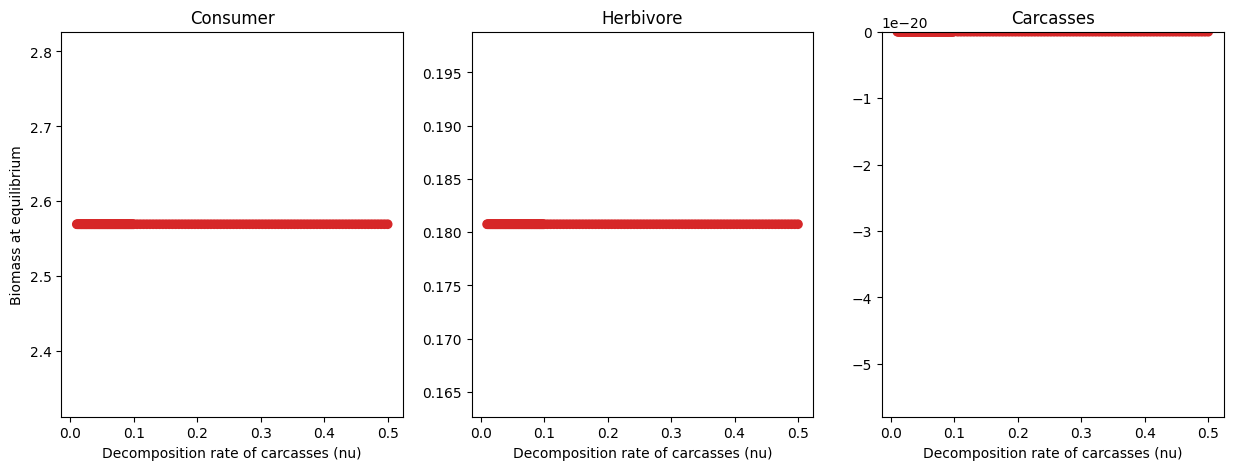

In [112]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))
for i, ax in enumerate(axes):
    ax.scatter(enulist, eqnu[:, i], color = eqnatcol)
    ymin = min(eqnu[:, i]) - min(eqnu[:, i])/10
    ymax = max(eqnu[:, i]) + max(eqnu[:, i])/10
    ax.set_ylim(ymin, ymax)
    ax.set_xlabel('Decomposition rate of carcasses (nu)')
axes[0].set_title('Consumer')
axes[0].hlines(y=0, xmin=enulist[0], xmax=enulist[-1], color='gray')
axes[0].set_ylabel('Biomass at equilibrium')
axes[1].set_title('Herbivore')
axes[2].set_title('Carcasses')